In [1]:
!pip install opendatasets neurokit2 --upgrade --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 693.1/693.1 kB 15.7 MB/s eta 0:00:00


In [2]:
import opendatasets as od
download_url = "https://www.kaggle.com/datasets/protobioengineering/mit-bih-arrhythmia-database-modern-2023/data"
od.download(download_url)

Dataset URL: https://www.kaggle.com/datasets/protobioengineering/mit-bih-arrhythmia-database-modern-2023


In [3]:
import os
import pandas as pd
import numpy as np
import scipy.signal
import neurokit2 as nk
from numba import njit
import json

In [4]:
def load_mlII_signals(data_dir):
    all_vectors = []
    patient_files = sorted([f for f in os.listdir(data_dir) if f.endswith(".csv")])

    for file in patient_files:
        filepath = os.path.join(data_dir, file)
        df = pd.read_csv(filepath)

        if 'MLII' in df.columns:
            mlII_signal = df['MLII'].values

            if len(mlII_signal) >= 650000:
                mlII_signal = mlII_signal[:650000]
            else:
                mlII_signal = np.pad(mlII_signal, (0, 650000 - len(mlII_signal)), 'constant')
            all_vectors.append(mlII_signal)
        else:
            print(f"MLII not found in {file}, skipping.")


    return np.stack(all_vectors, axis=1)


In [5]:
data_path = '/content/mit-bih-arrhythmia-database-modern-2023'
mlII_matrix = load_mlII_signals(data_path)
print("Data shape:", mlII_matrix.shape)

MLII not found in 102.csv, skipping.
MLII not found in 104.csv, skipping.
Data shape: (650000, 46)


In [6]:
np.random.seed(42)

def jitter(signal, sigma=0.05):

    return signal + np.random.normal(0, sigma, size=signal.shape)

def scaling(signal, factor_range=(0.9, 1.1)):

    factor = np.random.uniform(*factor_range)
    return signal * factor

def time_warp(signal, warp_amount=2000):

    warped = scipy.signal.resample(signal, len(signal) + warp_amount)
    return warped[:len(signal)]

def generate_augmented_signals(signal, num_augments=2):
    augmented = [signal]
    for _ in range(num_augments):
        aug = jitter(signal)
        aug = scaling(aug)
        aug = time_warp(aug)
        augmented.append(aug)
    return augmented

def expand_dataset(ecg_matrix, num_augments_per_signal=2):
    original_len, num_signals = ecg_matrix.shape
    all_signals = []

    for i in range(num_signals):
        signal = ecg_matrix[:, i]
        augmented_versions = generate_augmented_signals(signal, num_augments=num_augments_per_signal)
        all_signals.extend(augmented_versions)

    return np.stack(all_signals, axis=1)

In [7]:
augmented_matrix = expand_dataset(mlII_matrix, num_augments_per_signal=1)

print("Original shape:", mlII_matrix.shape)
print("Augmented shape:", augmented_matrix.shape)

Original shape: (650000, 46)
Augmented shape: (650000, 92)


In [8]:
fs = 360

@njit
def refine_r_peaks(signal, r_peaks, window=100):
    refined_peaks = []
    for idx in r_peaks:
        start = max(0, idx - window)
        end = min(len(signal), idx + window)
        segment = signal[start:end]
        pos_idx = segment.argmax()
        local_peak = pos_idx + start
        refined_peaks.append(local_peak)
    return np.array(refined_peaks)

all_refined_r_peaks = []

for i in range(augmented_matrix.shape[1]):
    signal = augmented_matrix[:, i]

    try:

        signal = signal - np.mean(signal)
        signal = signal / np.std(signal)


        _, info = nk.ecg_peaks(signal, sampling_rate=fs)
        r_peaks = info["ECG_R_Peaks"]


        refined_peaks = refine_r_peaks(signal, r_peaks)
        all_refined_r_peaks.append(refined_peaks)

    except Exception as e:
        print(f" Skipped patient {i+1} due to error: {e}")
        all_refined_r_peaks.append([])

print("\n Done! All patients processed.")


 Done! All patients processed.


In [9]:
import matplotlib.pyplot as plt

def plot_ecg_window(signal, r_peaks, start, end, patient_idx):
    plt.figure(figsize=(15, 4))
    plt.plot(range(start, end), signal[start:end], label="ECG Signal")


    window_peaks = [i for i in r_peaks if start <= i < end]
    plt.plot(window_peaks, signal[window_peaks], "ro", label="R-peaks")

    plt.title(f"Patient {patient_idx} | ECG Signal from {start} to {end}")
    plt.xlabel("Sample Index")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True)
    plt.show()


    print(f" Patient {patient_idx} | Total R-peaks: {len(r_peaks)} | R-peaks in window: {len(window_peaks)}")


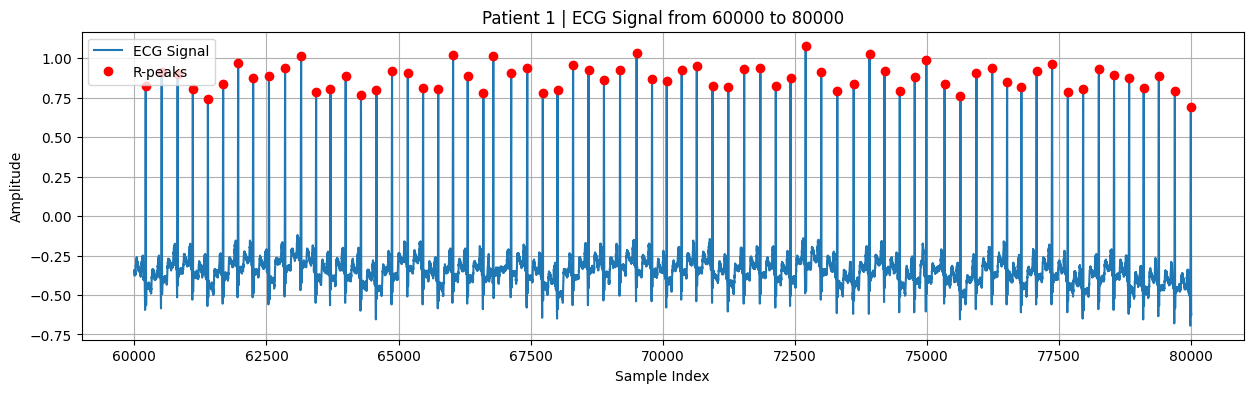

 Patient 1 | Total R-peaks: 2271 | R-peaks in window: 69


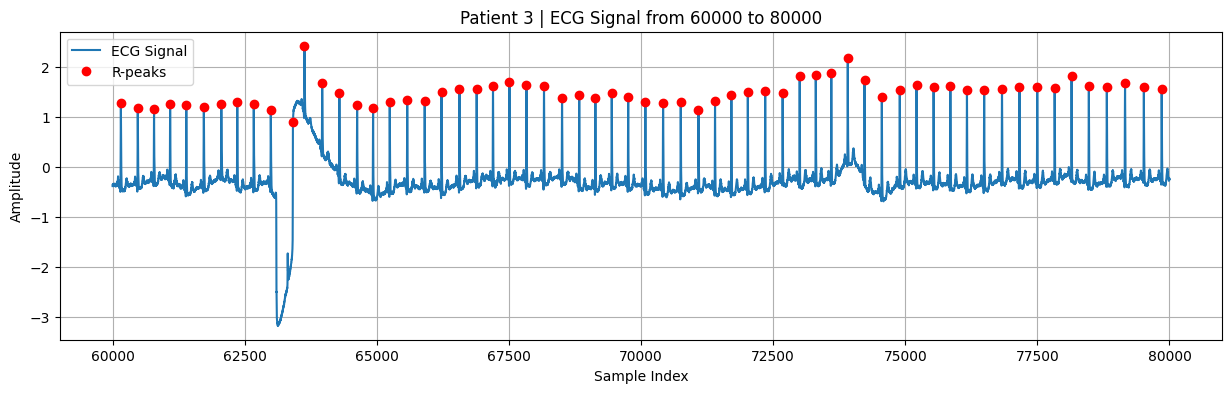

 Patient 3 | Total R-peaks: 1869 | R-peaks in window: 62


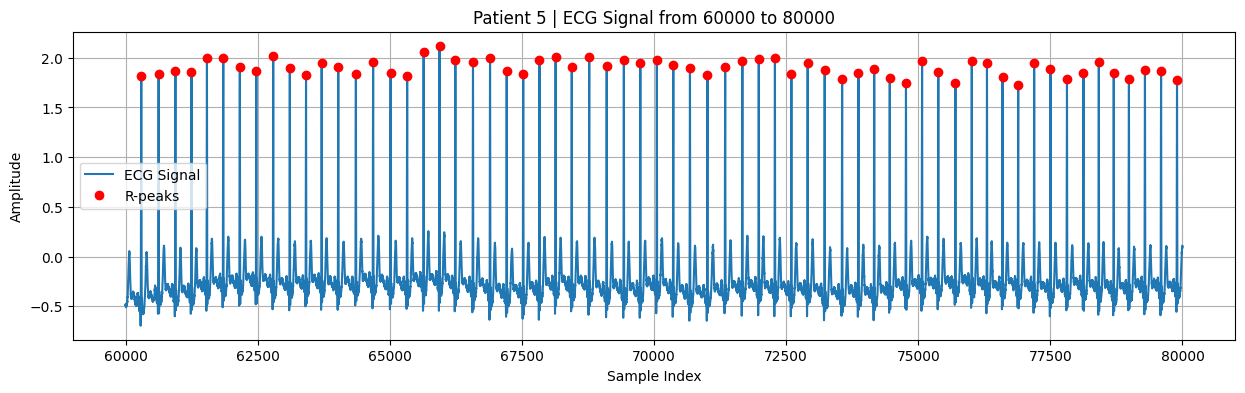

 Patient 5 | Total R-peaks: 2084 | R-peaks in window: 64


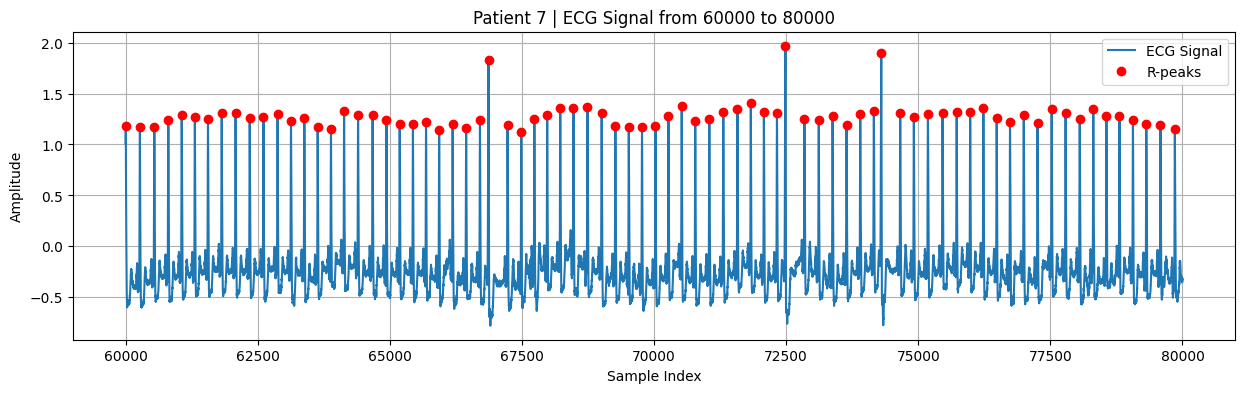

 Patient 7 | Total R-peaks: 2571 | R-peaks in window: 78


In [10]:
for patient_index in [0 , 2 , 4 ,6]:
  signal = augmented_matrix[:, patient_index]
  r_peaks = all_refined_r_peaks[patient_index]

  plot_ecg_window(signal, r_peaks, start=60000, end=80000, patient_idx=patient_index + 1)


In [11]:
def create_X_y_from_raw(data_matrix, refined_peaks_list, window_size=50):
    X_all, y_all = [], []

    for i in range(data_matrix.shape[1]):
        signal = data_matrix[:, i]
        r_peaks = refined_peaks_list[i]


        label = np.zeros(len(signal), dtype=int)
        label[r_peaks] = 1


        usable_len = (len(signal) // window_size) * window_size
        signal = signal[:usable_len]
        label = label[:usable_len]


        X = signal.reshape(-1, window_size, 1)
        y = label.reshape(-1, window_size).sum(axis=1) > 0
        y = y.astype(int)

        X_all.append(X)
        y_all.append(y)

    return np.concatenate(X_all, axis=0), np.concatenate(y_all, axis=0)


In [12]:
def load_patient_split(split_path="patient_split.json"):
    with open(split_path, "r") as f:
        return json.load(f)


def get_data_by_split(ecg_matrix, labels, split):
    train_data = ecg_matrix[:, split["train"]]
    val_data   = ecg_matrix[:, split["val"]]
    test_data  = ecg_matrix[:, split["test"]]

    train_labels = [labels[i] for i in split["train"]]
    val_labels   = [labels[i] for i in split["val"]]
    test_labels  = [labels[i] for i in split["test"]]

    return (train_data, train_labels), (val_data, val_labels), (test_data, test_labels)



split = load_patient_split("patient_split.json")

(train_data, train_labels), (val_data, val_labels), (test_data, test_labels) = get_data_by_split(augmented_matrix, all_refined_r_peaks, split)


X_train, y_train = create_X_y_from_raw(train_data, train_labels)
X_val, y_val     = create_X_y_from_raw(val_data, val_labels)
X_test, y_test   = create_X_y_from_raw(test_data, test_labels)

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)


Train: (780000, 50, 1) (780000,)
Val:   (104000, 50, 1) (104000,)
Test:  (104000, 50, 1) (104000,)


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, GRU, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.metrics import RootMeanSquaredError, MeanAbsoluteError
from sklearn.metrics import mean_squared_error

In [14]:
#GRU Model
def build_simple_gru_classifier(timesteps, features):
    inputs = Input(shape=(timesteps, features))
    x = GRU(64)(inputs)
    outputs = Dense(1, activation='sigmoid')(x)
    model = Model(inputs, outputs)
    return model

timesteps = X_train.shape[1]
features = X_train.shape[2]

model = build_simple_gru_classifier(timesteps, features)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 50, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,929 (50.50 KB)

 Trainable params: 12,929 (50.50 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
batch_sizes = [32, 64, 128]
best_model_path = "/content/best_overall_gru_model.keras"

batch_val_losses = {}
batch_rmse_scores = {}
batch_histories = {}
best_val_loss = np.inf
best_batch_size = None

# batch size
for batch_size in batch_sizes:
    print(f"\n Training with batch size {batch_size}...")

    model = build_simple_gru_classifier(timesteps, features)
    model.compile(
        optimizer=Adam(0.001),
        loss='binary_crossentropy',
        metrics=[
            'Accuracy',
            RootMeanSquaredError(name='RMSE'),
            MeanAbsoluteError(name='MAE')
        ]
    )

    model_path = f"/content/best_gru_model_bs{batch_size}.keras"

    checkpoint = ModelCheckpoint(
        filepath=model_path,
        monitor='val_loss',
        save_best_only=True,
        mode='min',
        verbose=1
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    )

    history = model.fit(
        X_train, y_train,
        epochs=10,
        batch_size=batch_size,
        validation_data=(X_val, y_val),
        callbacks=[checkpoint, early_stop],
        verbose=1
    )

    batch_histories[batch_size] = history

    # Load best model
    best_model = tf.keras.models.load_model(model_path)

    # Predict on test set
    y_pred = best_model.predict(X_test).flatten()
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    val_loss = min(history.history['val_loss'])

    print(f" Batch {batch_size} - Best Val Loss: {val_loss:.6f}, Test RMSE: {test_rmse:.6f}")

    batch_val_losses[batch_size] = val_loss
    batch_rmse_scores[batch_size] = test_rmse

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_batch_size = batch_size
        best_model.save(best_model_path)
        print(f" New Best Overall GRU Model Saved (Batch {batch_size})")

# Summary
print("\n Summary:")
for bs in batch_sizes:
    print(f"Batch {bs:3} → Val Loss: {batch_val_losses[bs]:.6f}, Test RMSE: {batch_rmse_scores[bs]:.6f}")
print(f"\n Best Batch Size: {best_batch_size} with Val Loss: {best_val_loss:.6f}")


 Training with batch size 32...
Epoch 1/10
24368/24375 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - Accuracy: 0.9636 - MAE: 0.0586 - RMSE: 0.1665 - loss: 0.1051
Epoch 1: val_loss improved from inf to 0.06092, saving model to /content/best_gru_model_bs32.keras
24375/24375 ━━━━━━━━━━━━━━━━━━━━ 158s 6ms/step - Accuracy: 0.9636 - MAE: 0.0586 - RMSE: 0.1665 - loss: 0.1051 - val_Accuracy: 0.9801 - val_MAE: 0.0389 - val_RMSE: 0.1296 - val_loss: 0.0609
Epoch 2/10
24371/24375 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Accuracy: 0.9810 - MAE: 0.0295 - RMSE: 0.1209 - loss: 0.0541
Epoch 2: val_loss improved from 0.06092 to 0.05949, saving model to /content/best_gru_model_bs32.keras
24375/24375 ━━━━━━━━━━━━━━━━━━━━ 186s 6ms/step - Accuracy: 0.9810 - MAE: 0.0295 - RMSE: 0.1209 - loss: 0.0541 - val_Accuracy: 0.9784 - val_MAE: 0.0365 - val_RMSE: 0.1286 - val_loss: 0.0595
Epoch 3/10
24373/24375 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Accuracy: 0.9821 - MAE: 0.0273 - RMSE: 0.1166 - loss: 0.0498
Epoch 3: val_loss improved fro

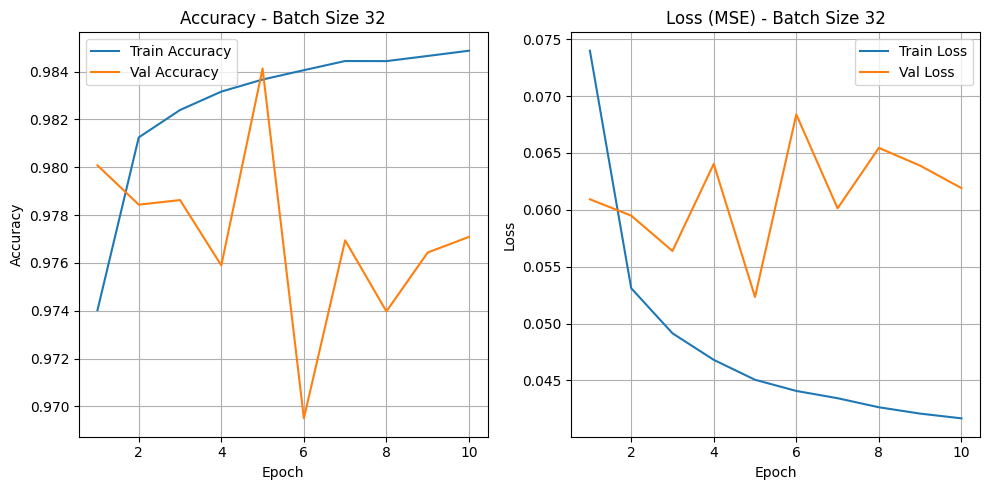

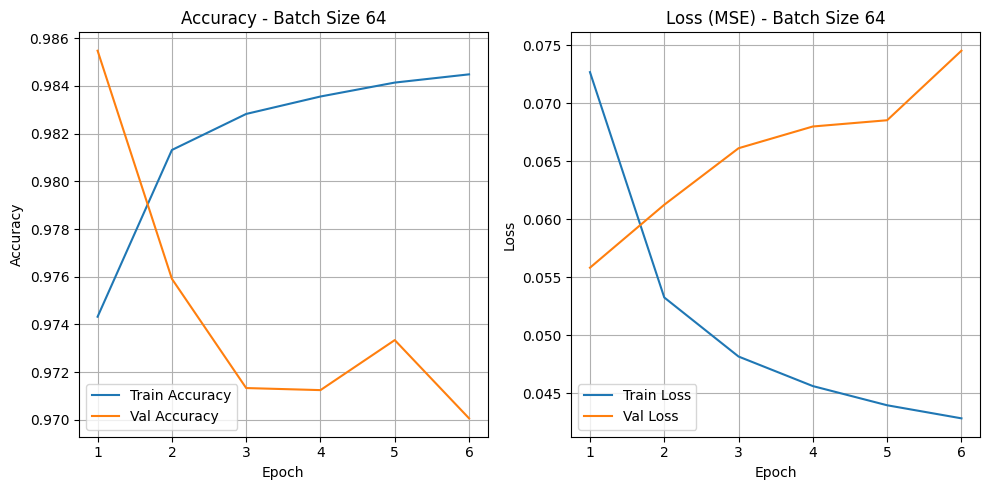

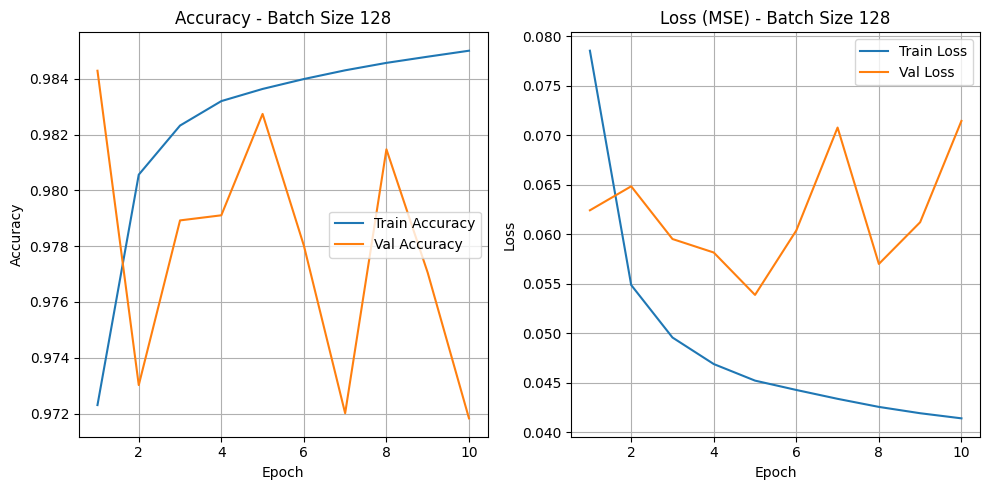

In [23]:
for bs in batch_sizes:
    hist = batch_histories[bs].history
    epochs = range(1, len(hist['loss']) + 1)

    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    if 'Accuracy' in hist:
        plt.plot(epochs, hist['Accuracy'], label='Train Accuracy')
        plt.plot(epochs, hist['val_Accuracy'], label='Val Accuracy')
        plt.title(f"Accuracy - Batch Size {bs}")
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs, hist['loss'], label='Train Loss')
    plt.plot(epochs, hist['val_loss'], label='Val Loss')
    plt.title(f"Loss (MSE) - Batch Size {bs}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()


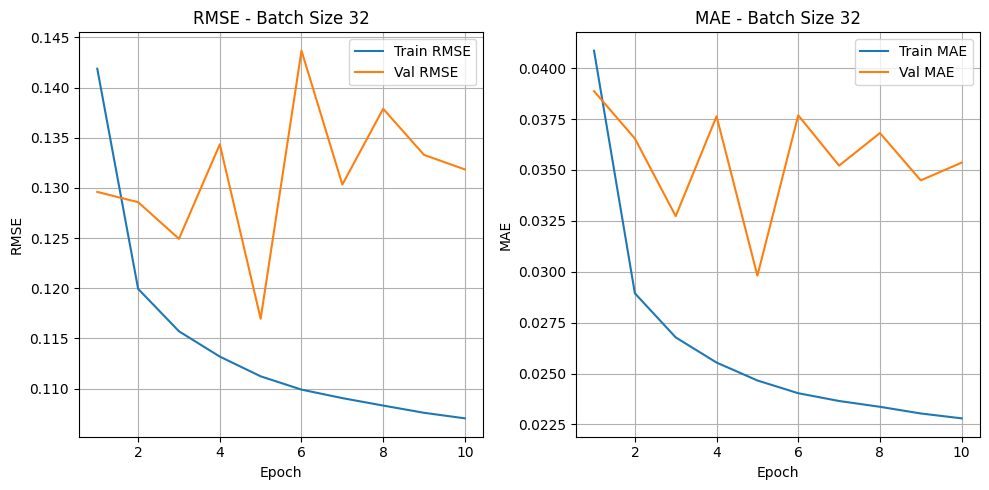

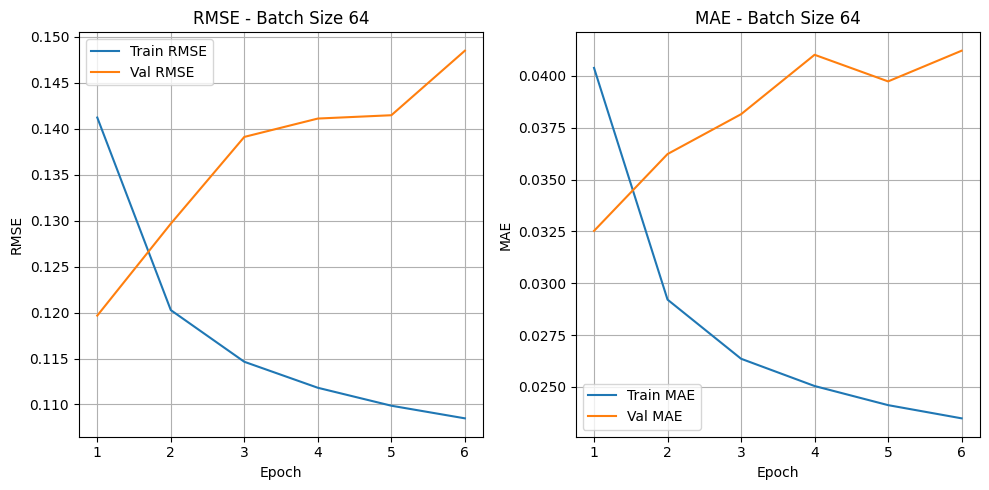

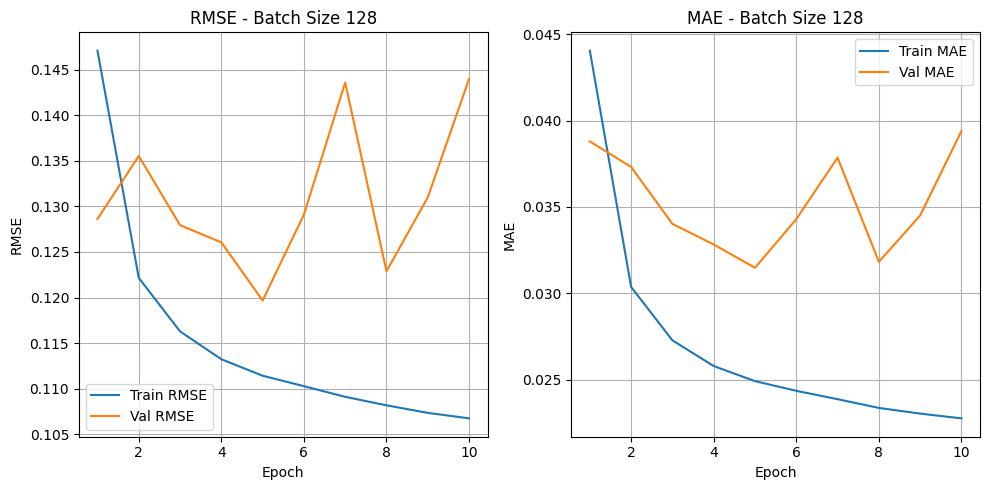

In [24]:
for bs in batch_sizes:
    hist = batch_histories[bs].history
    epochs = range(1, len(hist['RMSE']) + 1)

    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, hist['RMSE'], label='Train RMSE')
    plt.plot(epochs, hist['val_RMSE'], label='Val RMSE')
    plt.title(f"RMSE - Batch Size {bs}")
    plt.xlabel("Epoch")
    plt.ylabel("RMSE")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs, hist['MAE'], label='Train MAE')
    plt.plot(epochs, hist['val_MAE'], label='Val MAE')
    plt.title(f"MAE - Batch Size {bs}")
    plt.xlabel("Epoch")
    plt.ylabel("MAE")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()


In [25]:
for bs in batch_sizes:
    hist = batch_histories[bs].history
    if 'accuracy' in hist:
        epochs = range(1, len(hist['accuracy']) + 1)

        plt.figure(figsize=(8, 5))
        plt.plot(epochs, hist['accuracy'], label='Train Accuracy')
        plt.plot(epochs, hist['val_accuracy'], label='Val Accuracy')
        plt.title(f"Accuracy - Batch Size {bs}")
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.grid(True)
        plt.show()


In [26]:
from tensorflow.keras.models import load_model

# Load trained model
model = load_model("/content/best_overall_gru_model.keras")


In [27]:

y_pred_probs = model.predict(X_test)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()


3250/3250 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step


In [28]:
from sklearn.metrics import f1_score, confusion_matrix, classification_report

# F1 Score
f1 = f1_score(y_test, y_pred)
print(f" F1 Score: {f1:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\n Classification Report:")
print(classification_report(y_test, y_pred, digits=4))


 F1 Score: 0.8699

 Classification Report:
              precision    recall  f1-score   support

           0     0.9652    0.9922    0.9786     88056
           1     0.9493    0.8027    0.8699     15944

    accuracy                         0.9632    104000
   macro avg     0.9573    0.8975    0.9242    104000
weighted avg     0.9628    0.9632    0.9619    104000



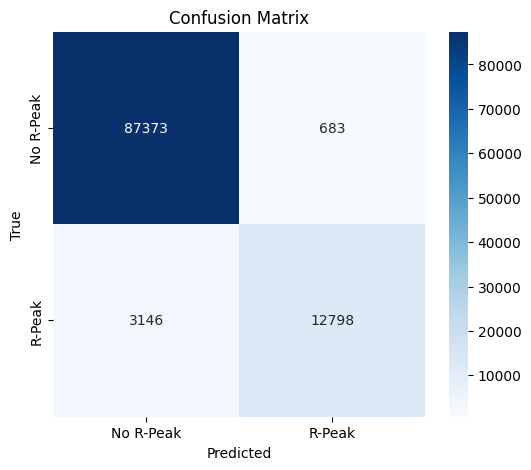

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No R-Peak", "R-Peak"], yticklabels=["No R-Peak", "R-Peak"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()
